## **Pengolahan Citra Digital: Pseudocolor**

pengolahan citra digital ini mempraktikkan metode Pseudocolor untuk mengubah gambar grayscale (hitam putih) menjadi tampilan berwarna menggunakan Python dan OpenCV.

Catatan: Pseudocolor memetakan tingkat keabuan ke warna tertentu. Hasilnya berwarna, tetapi bukan perkiraan warna asli objek seperti pada metode Image Colorization berbasis AI.

# Memanggil Library

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image
from io import BytesIO

# Mengupload Gambar

In [2]:
uploaded = files.upload()

if not uploaded:
    raise ValueError("Belum ada gambar yang diunggah.")

nama_file = next(iter(uploaded))
data_gambar = uploaded[nama_file]

print(f"Nama file: {nama_file}")
print(f"Ukuran file: {len(data_gambar):,} byte")

Saving WhatsApp Image 2026-10-28 at 17.33.09.jpeg to WhatsApp Image 2026-10-28 at 17.33.09.jpeg
Nama file: WhatsApp Image 2026-10-28 at 17.33.09.jpeg
Ukuran file: 146,305 byte


# Membaca gambar sebagai grayscale

In [3]:
img = Image.open(BytesIO(data_gambar)).convert("L")
gray = np.array(img)

print("Dimensi gambar (tinggi, lebar):", gray.shape)
print("Tipe data:", gray.dtype)
print("Nilai piksel minimum:", gray.min())
print("Nilai piksel maksimum:", gray.max())

Dimensi gambar (tinggi, lebar): (1600, 709)
Tipe data: uint8
Nilai piksel minimum: 2
Nilai piksel maksimum: 255


# Menampilkan gambar asli

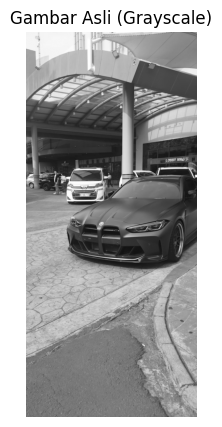

In [4]:
plt.figure(figsize=(7, 5))
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Gambar Asli (Grayscale)")
plt.axis("off")
plt.show()

# Menerapkan metode Pseudocolor

In [5]:
# Memetakan intensitas grayscale menjadi warna
hasil_bgr = cv2.applyColorMap(gray, cv2.COLORMAP_JET)

# OpenCV menyimpan kanal warna dalam urutan BGR.
# Matplotlib membutuhkan urutan RGB untuk menampilkan warna dengan benar.
hasil_rgb = cv2.cvtColor(hasil_bgr, cv2.COLOR_BGR2RGB)

print("Dimensi gambar hasil:", hasil_rgb.shape)
print("Jumlah kanal warna hasil:", hasil_rgb.shape[2])

Dimensi gambar hasil: (1600, 709, 3)
Jumlah kanal warna hasil: 3


# Membandingkan gambar sebelum dan sesudah

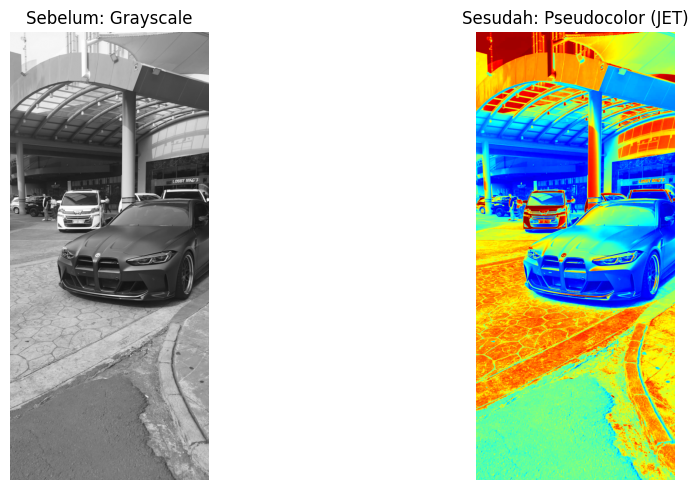

In [6]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Sebelum: Grayscale")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hasil_rgb)
plt.title("Sesudah: Pseudocolor (JET)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Menyimpan dan mengunduh hasil

In [7]:
hasil_file = "hasil_pseudocolor.png"

# Konversi kembali ke BGR agar sesuai dengan format yang digunakan OpenCV saat menyimpan.
hasil_simpan = cv2.cvtColor(hasil_rgb, cv2.COLOR_RGB2BGR)
berhasil = cv2.imwrite(hasil_file, hasil_simpan)

if berhasil:
    print(f"Hasil berhasil disimpan sebagai: {hasil_file}")
    files.download(hasil_file)
else:
    raise IOError("Gambar hasil gagal disimpan.")

Hasil berhasil disimpan sebagai: hasil_pseudocolor.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>